## INF201 - Deliverable 1

### Group info:

ID: `G5_4`

Members:
* Stig Espen Paulsberg
* Vinicius Millan Santa Catharina
* Zaur Kambiev 

### Imports

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml

### Client ID

Read the client ID from `config.yaml`

In [5]:
with open("config.yaml") as file:
    config = yaml.safe_load(file)

client_id = config["met_api"]["client_id"]

### Task 1

Request data from Meteorologisk Institutt 

(example source https://frost.met.no/python_example.html)

In [30]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id, ''))

# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print(f'Error! Returned status code {r.status_code}')
    print(f'Message: {json['error']['message']}')
    print(f'Reason: {json['error']['reason']}')

Data retrieved from frost.met.no!


Convert JSON into DataFrame

In [ ]:
# This will return a Dataframe with all of the observations in a table format
table = pd.DataFrame()
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    table = pd.concat([table, row], ignore_index=True)

# These additional columns will be kept
columns = ['referenceTime', 'timeOffset', 'qualityCode', 'value', 'unit']
df = table[columns]

# Convert the time value to something Python understands
df['referenceTime'] = pd.to_datetime(df['referenceTime'])

df.head()

,referenceTime,timeOffset,qualityCode,value,unit
0,2025-01-01 00:00:00+00:00,PT0H,0.0,-5.2,degC
1,2025-01-01 00:00:00+00:00,PT6H,NaN,-2.8,degC
2,2025-01-02 00:00:00+00:00,PT0H,0.0,-11.5,degC
3,2025-01-02 00:00:00+00:00,PT6H,NaN,-7.2,degC
4,2025-01-03 00:00:00+00:00,PT0H,0.0,-8.9,degC


Check for missing values

In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 728 entries, 0 to 727
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   referenceTime  728 non-null    datetime64[us, UTC]
 1   timeOffset     728 non-null    str                
 2   qualityCode    364 non-null    float64            
 3   value          728 non-null    float64            
 4   unit           728 non-null    str                
dtypes: datetime64[us, UTC](1), float64(2), str(2)
memory usage: 28.6 KB


Observations:
* We have two entries per day: `timeOffset = PT0H` and `timeOffset = PT6H`. 

* For `timeOffset = PT6H`, the `qualityCode` field is not filled. 

Decision: 
* We will use only entries with `timeOffset = PT0H`, as they have `qualityCode` of `0`, indicating the highest data quality.

In [70]:
df = df[df["timeOffset"] == "PT0H"]

Make a nicely formatted plot

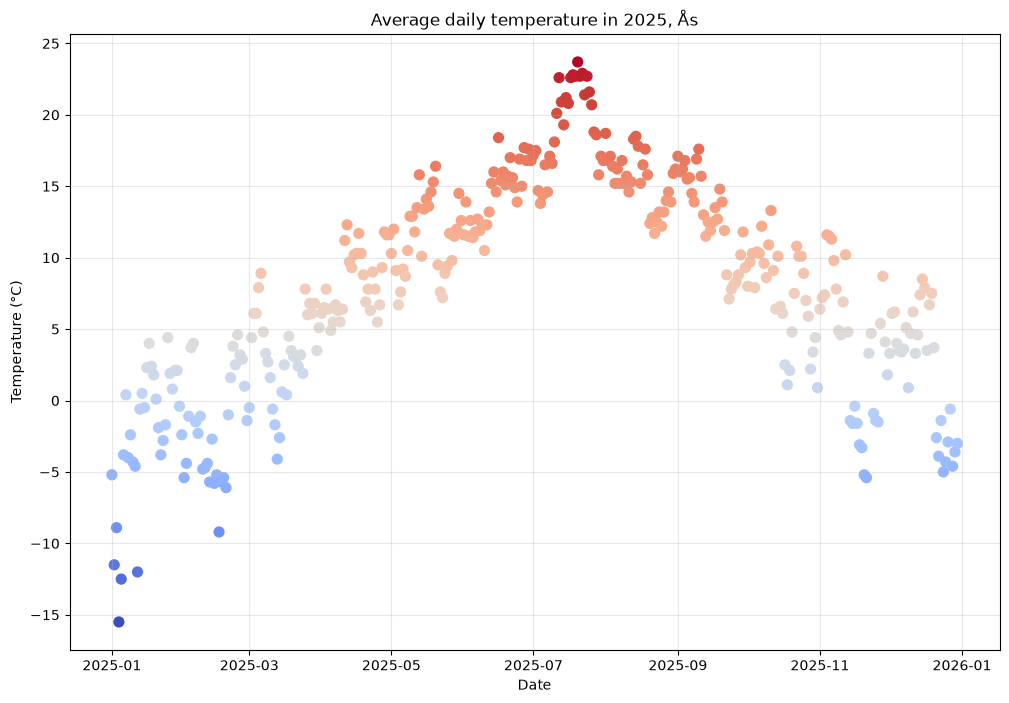

In [71]:
plt.figure(figsize=(12, 8))
temp_fig = plt.scatter(x=df['referenceTime'],
                       y=df['value'],
                       c=df['value'],
                       cmap='coolwarm',
                       s=50)

plt.grid(True, alpha=0.3)
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.title('Average daily temperature in 2025, Ås')
plt.show()

Print a nicely formatted summary table

In [ ]:
stats = df["value"].agg(["mean", "median", "min", "max"])

print(
    f"{"Statistic":^20}{"Value":^20}\n"
    f"stats"
    f""
    f""
)


     Statistic             Value        


In [ ]:
from tabulate import tabulate

def summary_table(df):
    """
    Function to create a summary table of the temperature data.
    """
    # Calculate descriptive statistics
    summary = df["value"].agg(["mean", "median", "min", "max"])

    # Assign readable labels to the statistics
    summary.index = ["Mean", "Median", "Minimum", "Maximum"]

    # Display the summary as a formatted table
    print("Summary of Daily Air Temperature in Ås (2025)")

    print(tabulate(
        summary.reset_index(),
        headers=["Statistic", "Temperature (°C)"],
        tablefmt="outline",
        showindex=False,
        floatfmt=".2f"
    )
    )

### Task 2

In [ ]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters_precip = {
 'sources': 'SN17850',
 'elements': 'sum(precipitation_amount P1D)',
 'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters_precip, auth=(client_id,''))
# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data_precip = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])


Data retrieved from frost.met.no!


In [ ]:
# This will return a Dataframe with all of the observations in a table format
# Intructions: https://frost.met.no/python_example.html

rows_precip = []

for i in range(len(data_precip)):
    row = pd.DataFrame(data_precip[i]['observations'])
    row['referenceTime'] = data_precip[i]['referenceTime']
    row['sourceId'] = data_precip[i]['sourceId']
    rows_precip.append(row)

df_precip = pd.concat(rows_precip, ignore_index=True)

df_precip['referenceTime'] = pd.to_datetime(df_precip['referenceTime'])

df_precip.head()

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId
0,sum(precipitation_amount P1D),5.4,mm,PT18H,P1D,0,C,2,NaN,2025-01-01 00:00:00+00:00,SN17850:0
1,sum(precipitation_amount P1D),6.6,mm,PT6H,P1D,0,C,2,0.0,2025-01-01 00:00:00+00:00,SN17850:0
2,sum(precipitation_amount P1D),0.0,mm,PT18H,P1D,0,C,2,NaN,2025-01-02 00:00:00+00:00,SN17850:0
3,sum(precipitation_amount P1D),1.9,mm,PT6H,P1D,0,C,2,0.0,2025-01-02 00:00:00+00:00,SN17850:0
4,sum(precipitation_amount P1D),0.1,mm,PT18H,P1D,0,C,2,NaN,2025-01-03 00:00:00+00:00,SN17850:0


In [ ]:
# Create a df with the precipiation measuremente of the PT6H timeOffset

df_precip_6H = df_precip[df_precip['timeOffset'] == "PT6H"]
df_precip_6H.head()

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId
1,sum(precipitation_amount P1D),6.6,mm,PT6H,P1D,0,C,2,0.0,2025-01-01 00:00:00+00:00,SN17850:0
3,sum(precipitation_amount P1D),1.9,mm,PT6H,P1D,0,C,2,0.0,2025-01-02 00:00:00+00:00,SN17850:0
5,sum(precipitation_amount P1D),0.1,mm,PT6H,P1D,0,C,2,0.0,2025-01-03 00:00:00+00:00,SN17850:0
7,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,2025-01-04 00:00:00+00:00,SN17850:0
9,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,2025-01-05 00:00:00+00:00,SN17850:0


In [ ]:
# Create a list with the total precipitation of each month for the PT6H timeOffset
monthly_total = []

for i in range(1,13):
    total = df_precip_6H[df_precip_6H['referenceTime'].dt.month==i]['value'].sum()
    monthly_total.append(total)

monthly_total

[np.float64(86.4),
 np.float64(38.800000000000004),
 np.float64(15.7),
 np.float64(21.6),
 np.float64(35.400000000000006),
 np.float64(93.3),
 np.float64(77.00000000000001),
 np.float64(110.30000000000001),
 np.float64(145.6),
 np.float64(124.89999999999999),
 np.float64(84.89999999999998),
 np.float64(116.3)]

In [ ]:
# one date for each month (15)
months_dates = []

for i in range(1,13):
    date = "2025-"+str(i)+"-15"
    months_dates.append(date)

months_dates = pd.to_datetime(months_dates)


DatetimeIndex(['2025-01-15', '2025-02-15', '2025-03-15', '2025-04-15',
               '2025-05-15', '2025-06-15', '2025-07-15', '2025-08-15',
               '2025-09-15', '2025-10-15', '2025-11-15', '2025-12-15'],
              dtype='datetime64[us]', freq=None)


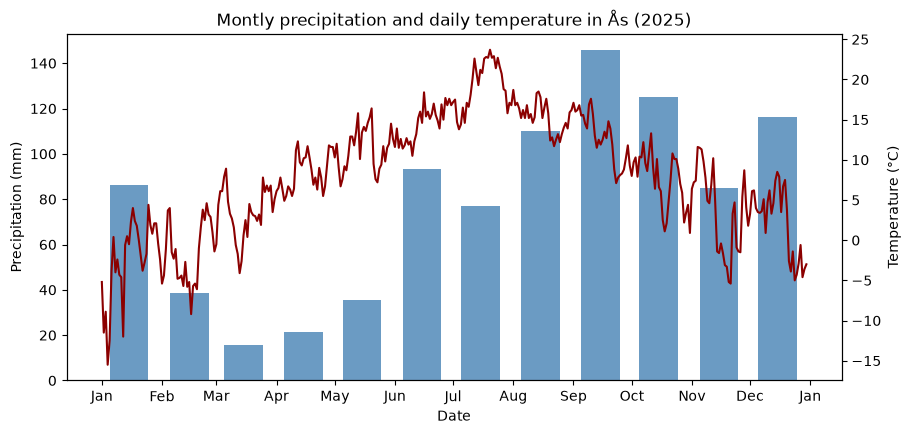

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax2 = ax1.twinx()

ax1.bar(
    months_dates,        
    monthly_total,
    width=20,
    alpha=0.8,
    color='steelblue'
)
ax1.set_ylabel("Precipitation (mm)")
ax1.set_xlabel("Date")
ax1.set_title("Montly precipitation and daily temperature in Ås (2025)")
ax2.plot(
    df_temp['referenceTime'],
    df_temp['value'],
    color='darkred'
)
ax2.xaxis.set_major_locator(mdates.MonthLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax2.set_ylabel("Temperature (°C)")

plt.show()

### Task 3

In [ ]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'

# -- Year 1925 --
parameters_1925 = {
 'sources': 'SN17850',
 'elements': 'mean(air_temperature P1D)',
 'referencetime': '1925-01-01/1925-12-31',
}

r_1925 = requests.get(endpoint, parameters_1925, auth=(client_id,''))
json_1925 = r_1925.json()

# -- Year 2025 --
parameters_2025 = {
 'sources': 'SN17850',
 'elements': 'mean(air_temperature P1D)',
 'referencetime': '2025-01-01/2025-12-31',
}

r_2025 = requests.get(endpoint, parameters_2025, auth=(client_id,''))
json_2025 = r_2025.json()



In [ ]:
# Check if the request worked, print out any errors

# -- Year 1925 --
if r_1925.status_code == 200:
    data_1925 = json_1925['data']
    print('1925: data retrieved from frost.met.no!')
else:
    print('1925: Error! Returned status code %s' % r_1925.status_code)
    print('Message: %s' % json_1925['error']['message'])
    print('Reason: %s' % json_1925['error']['reason'])

# -- Year 2025 --
if r_2025.status_code == 200:
    data_2025 = json_2025['data']
    print('2025: data retrieved from frost.met.no!')
else:
    print('2025: Error! Returned status code %s' % r_2025.status_code)
    print('Message: %s' % json_2025['error']['message'])
    print('Reason: %s' % json_2025['error']['reason'])



1925: data retrieved from frost.met.no!
2025: data retrieved from frost.met.no!


In [ ]:
# This will return a Dataframe with all of the observations in a table format
# Intructions: https://frost.met.no/python_example.html

# --- DataFrame 1925 ---
rows_1925 = []

for i in range(len(data_1925)):
    row = pd.DataFrame(data_1925[i]['observations'])
    row['referenceTime'] = data_1925[i]['referenceTime']
    row['sourceId'] = data_1925[i]['sourceId']
    rows_1925.append(row)

df_1925 = pd.concat(rows_1925, ignore_index=True)

# --- DataFrame 2025 ---
rows_2025 = []

for i in range(len(data_2025)):
    row = pd.DataFrame(data_2025[i]['observations'])
    row['referenceTime'] = data_2025[i]['referenceTime']
    row['sourceId'] = data_2025[i]['sourceId']
    rows_2025.append(row)

df_2025 = pd.concat(rows_2025, ignore_index=True)


In [ ]:
# Convert the time column from text to real datetime values
df_1925['referenceTime'] = pd.to_datetime(df_1925['referenceTime'])
df_2025['referenceTime'] = pd.to_datetime(df_2025['referenceTime'])

# Keep only one series for 2025 (timeOffset PT0H) to get one row per day
df_2025_0H = df_2025[df_2025['timeOffset'] == 'PT0H']


In [ ]:
# Day of the year (1-365) lets both years share the same x-axis
df_1925['day'] = df_1925['referenceTime'].dt.dayofyear
df_2025_0H['day'] = df_2025_0H['referenceTime'].dt.dayofyear

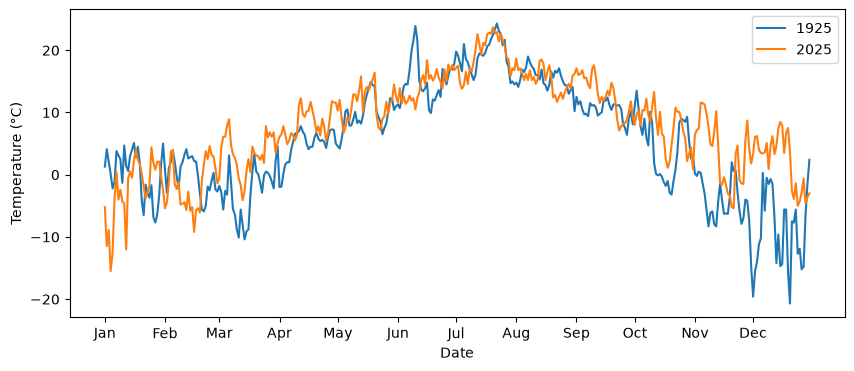

In [ ]:
#Plotting the air temperature data
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(df_1925['day'], df_1925['value'], label='1925')
ax.plot(df_2025_0H['day'], df_2025_0H['value'], label='2025')

# Ticks at the first day of each month (non-leap year)
ax.set_xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335])
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

ax.set_ylabel("Temperature (°C)")
ax.set_xlabel("Date")
ax.legend()                                 
plt.show()

In [ ]:
# Creating a summary table of the air temperature data
summary_1925 = df_1925["value"].agg(["mean", "median","min", "max"])
summary_1925.index = ["Mean", "Median", "Minimum", "Maximum"]

summary_2025 = df_2025_0H["value"].agg(["mean", "median","min", "max"])
summary_2025.index = ["Mean", "Median", "Minimum", "Maximum"]

# Print the table: title and header
print("=" * 40)
print(f"|{'TEMPERATURE (°C)':^38}|")
print("=" * 40)
print(f"| {'YEAR':^10} | {'1925':^10} | {'2025':^10} |")
print("=" * 40)

# Print one row per statistic
print(f"| {'Mean':<10} | {summary_1925['Mean']:^10.2f} | {summary_2025['Mean']:^10.2f} |")
print("-" * 40)
print(f"| {'Median':<10} | {summary_1925['Median']:^10.2f} | {summary_2025['Median']:^10.2f} |")
print("-" * 40)
print(f"| {'Minimum':<10} | {summary_1925['Minimum']:^10.2f} | {summary_2025['Minimum']:^10.2f} |")
print("-" * 40)
print(f"| {'Maximum':<10} | {summary_1925['Maximum']:^10.2f} | {summary_2025['Maximum']:^10.2f} |")
print("=" * 40)

|           TEMPERATURE (°C)           |
|    YEAR    |    1925    |    2025    |
| Mean       |    5.31    |    7.90    |
----------------------------------------
| Median     |    5.30    |    8.40    |
----------------------------------------
| Minimum    |   -20.70   |   -15.50   |
----------------------------------------
| Maximum    |   24.30    |   23.70    |


### Task 4

### Task 5